CAR PRICE DATASET
   Year  Kms_Driven    Fuel Transmission  Owner  Engine  Max_Power    Mileage  \
0  2011      120033  Petrol    Automatic      3    1243        125  20.921747   
1  2024       81077     CNG       Manual      2    2150         91  19.003771   
2  2019       95474     CNG    Automatic      2    1560        150  20.968759   
3  2015      138515     CNG       Manual      2    1026        148  21.546199   
4  2012       78319  Diesel    Automatic      2     847        125  24.631156   

   Selling_Price  
0   8.774223e+05  
1   1.218875e+06  
2   1.310919e+06  
3   9.225783e+05  
4   1.011275e+06  

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Year           1000 non-null   int64  
 1   Kms_Driven     1000 non-null   int64  
 2   Fuel           1000 non-null   object 
 3   Transmission   1000 non-null 

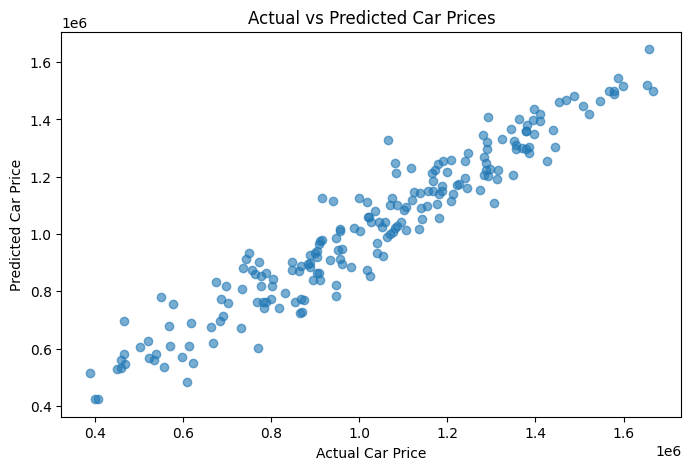


NEW CAR DETAILS
   Year  Kms_Driven  Owner  Engine  Max_Power  Mileage  Fuel_CNG  Fuel_Diesel  \
0  2020       30000      1    1500        100     18.5         0            0   

   Fuel_Petrol  Transmission_Automatic  Transmission_Manual  
0         True                       0                 True  

Predicted Car Price: Rs. 1111751.27


In [3]:

# CAR PRICE PREDICTION USING RANDOM FOREST REGRESSION

# Step 1: Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# Step 2: Create a sample car dataset
np.random.seed(42)

n = 1000

data = pd.DataFrame({
    'Year': np.random.randint(2005, 2026, n),
    'Kms_Driven': np.random.randint(5000, 150000, n),
    'Fuel': np.random.choice(
        ['Petrol', 'Diesel', 'CNG'], n
    ),
    'Transmission': np.random.choice(
        ['Manual', 'Automatic'], n
    ),
    'Owner': np.random.randint(1, 4, n),
    'Engine': np.random.randint(800, 2500, n),
    'Max_Power': np.random.randint(40, 200, n),
    'Mileage': np.random.uniform(10, 25, n)
})

# Step 3: Generate sample car prices
fuel_value = data['Fuel'].map({
    'Petrol': 0,
    'Diesel': 70000,
    'CNG': -30000
})

transmission_value = data['Transmission'].map({
    'Manual': 0,
    'Automatic': 100000
})

data['Selling_Price'] = (
    100000
    + (data['Year'] - 2005) * 30000
    - data['Kms_Driven'] * 1.5
    + data['Engine'] * 150
    + data['Max_Power'] * 3500
    + data['Mileage'] * 5000
    + fuel_value
    + transmission_value
    - (data['Owner'] - 1) * 40000
    + np.random.normal(0, 40000, n)
)

data['Selling_Price'] = data['Selling_Price'].clip(lower=30000)

print("CAR PRICE DATASET")
print(data.head())

# Step 4: Check dataset information
print("\nDataset Information:")
print(data.info())

# Step 5: Separate input and output variables
X = data.drop('Selling_Price', axis=1)
y = data['Selling_Price']

# Step 6: Convert categorical variables into numerical values
X = pd.get_dummies(X, columns=['Fuel', 'Transmission'])

# Step 7: Split the dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Step 8: Create Random Forest Regression model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Step 9: Train the model
model.fit(X_train, y_train)

print("\nModel Training Completed Successfully!")

# Step 10: Predict car prices
y_pred = model.predict(X_test)

print("\nPredicted Car Prices:")
print(y_pred[:10])

print("\nActual Car Prices:")
print(y_test.iloc[:10].values)

# Step 11: Evaluate model performance
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nMODEL PERFORMANCE")
print("Mean Absolute Error:", round(mae, 2))
print("Mean Squared Error:", round(mse, 2))
print("Root Mean Squared Error:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

# Step 12: Visualize actual and predicted prices
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.6)

plt.xlabel("Actual Car Price")
plt.ylabel("Predicted Car Price")
plt.title("Actual vs Predicted Car Prices")

plt.show()

# Step 13: Predict the price of a new car
new_car = pd.DataFrame([{
    'Year': 2020,
    'Kms_Driven': 30000,
    'Owner': 1,
    'Engine': 1500,
    'Max_Power': 100,
    'Mileage': 18.5,
    'Fuel': 'Petrol',
    'Transmission': 'Manual'
}])

# Convert categorical values into numerical values
new_car = pd.get_dummies(
    new_car,
    columns=['Fuel', 'Transmission']
)

# Match training dataset columns
new_car = new_car.reindex(
    columns=X.columns,
    fill_value=0
)

# Predict selling price
predicted_price = model.predict(new_car)

print("\nNEW CAR DETAILS")
print(new_car)

print("\nPredicted Car Price: Rs.",
      round(predicted_price[0], 2))
